# Partie H - Detection de fraude

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, confusion_matrix,
                             average_precision_score, ConfusionMatrixDisplay, PrecisionRecallDisplay)

SEED = 42
PATH = "bank_transactions.csv"

## 1. Chargement

In [2]:
df = pd.read_csv(PATH)
print(df.shape)
df.head()

(5000, 9)


,transaction_id,account_id,amount,hour,country,merchant_category,transactions_last_24h,average_amount_last_7d,is_fraud
0,TX000001,ACC0090,383.72,4,FR,ECOMMERCE,6,217.44,0
1,TX000002,ACC0774,516.48,0,BE,ECOMMERCE,1,275.06,0
2,TX000003,ACC0655,151.95,15,DE,GROCERY,1,100.82,0
3,TX000004,ACC0439,34.56,16,FR,GROCERY,4,33.88,0
4,TX000005,ACC0434,93.14,18,FR,TRANSPORT,0,276.66,0


## 2. Proportion de fraudes et valeurs manquantes

In [3]:
print(df["is_fraud"].value_counts(normalize=True).round(4))
print(df.isna().sum())

is_fraud
0    0.9486
1    0.0514
Name: proportion, dtype: float64
transaction_id             0
account_id                 0
amount                     0
hour                       0
country                   66
merchant_category         84
transactions_last_24h      0
average_amount_last_7d    75
is_fraud                   0
dtype: int64


## 3. Separation train/test stratifiee et exclusion des identifiants

In [4]:
X = df.drop(columns=["is_fraud", "transaction_id", "account_id"])
y = df["is_fraud"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print(len(X_train), y_train.mean(), len(X_test), y_test.mean())

3750 0.05146666666666667 1250 0.0512


## 4. Pipeline

In [5]:
num_cols = ["amount", "hour", "transactions_last_24h", "average_amount_last_7d"]
cat_cols = ["country", "merchant_category"]

preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])
model = Pipeline([
    ("prep", preprocess),
    ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                   class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)),
])

## 5. Seuil de decision (validation croisee sur le train uniquement)

In [6]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
proba_cv = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
seuils = np.linspace(0.05, 0.95, 91)
f1s = [f1_score(y_train, proba_cv >= t, zero_division=0) for t in seuils]
seuil = float(seuils[int(np.argmax(f1s))])
print("Seuil retenu :", round(seuil, 2))

Seuil retenu : 0.28


## 6. Evaluation sur le test

seuil 0.50
Precision : 0.174
Rappel    : 0.125
F1        : 0.145
[[1148   38]
 [  56    8]] 

seuil 0.28
Precision : 0.089
Rappel    : 0.344
F1        : 0.142
[[962 224]
 [ 42  22]] 

Average precision : 0.093
Reference (taux de fraude) : 0.051


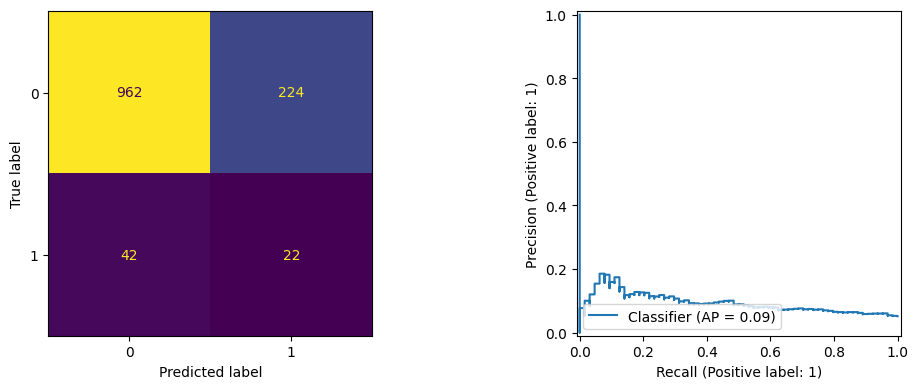

In [7]:
model.fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, 1]

for nom, t in [("seuil 0.50", 0.5), (f"seuil {seuil:.2f}", seuil)]:
    p = (proba >= t).astype(int)
    print(nom)
    print("Precision :", round(precision_score(y_test, p, zero_division=0), 3))
    print("Rappel    :", round(recall_score(y_test, p), 3))
    print("F1        :", round(f1_score(y_test, p), 3))
    print(confusion_matrix(y_test, p), "\n")

print("Average precision :", round(average_precision_score(y_test, proba), 3))
print("Reference (taux de fraude) :", round(y_test.mean(), 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, (proba >= seuil).astype(int), ax=ax[0], colorbar=False)
PrecisionRecallDisplay.from_predictions(y_test, proba, ax=ax[1])
plt.tight_layout(); plt.show()

## Questions d'analyse

1. **Accuracy insuffisante** : avec des classes desequilibrees, predire toujours "pas de fraude" donne une accuracy elevee sans detecter aucune fraude. Precision, rappel, F1 et average precision de la classe fraude sont necessaires.

2. **Compromis** : une fraude non detectee coute son montant ; un faux positif bloque un client legitime et mobilise des analystes. Reduire l'un augmente l'autre.

3. **Baisse du seuil** : le rappel augmente, la precision diminue en general, les faux positifs augmentent.

4. **Validation temporelle** : en production on predit le futur a partir du passe. Un decoupage aleatoire cree des fuites temporelles et ignore la derive des comportements, ce qui surestime les performances.